# LSTM + XGBoost — Activation / Optimizer Experiment

Derived from `runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb`. Three deliberate
differences from that notebook:

**1. The LSTM is loaded, not retrained.** The LSTM is frozen in this project — its architecture and
hyperparameters are adopted unchanged from the baseline study, and nothing here touches them.
Dropout is inactive at inference, so a saved model is deterministic and reproduces its
training-time predictions exactly. This notebook loads `models/v2_static/lstm_model.keras` and
asserts that it reproduces the recorded test RMSE of 5.9586. That removes ~12 minutes of CPU
training per run and guarantees every grid cell is compared against an identical LSTM.

**2. XGBoost hyperparameters are searched, not hardcoded.** The static notebook hardcodes
`XGB_STATIC_PARAMS`. Here the randomised-search-plus-refinement procedure from
`LSTM_XGBoost_Ensemble_Precipitation_REFACTORED 2.2.ipynb` (cell 7 search space, cell 23 procedure)
runs inline: 40 `ParameterSampler` draws plus 30 refinement fits, each scored as RMSE **in inches**
on the last 12% of training, chronologically.

**3. Ensemble weights are derived per grid cell.** They were already derived rather than hardcoded
in the static notebook — normalised reciprocals of each component's validation RMSE. That mechanism
is unchanged, but because each grid cell changes XGBoost's validation RMSE, the weights are
recomputed for every cell and reported alongside it.

## The experiment, and an honest note on terminology

XGBoost has **no optimizer and no activation function** — those are neural-network concepts. It is
not a gradient-descent learner over a parameterised function with layerwise nonlinearities; it is a
stage-wise additive model. This notebook does not pretend the terms transfer. It varies the two
settings that are XGBoost's genuine counterparts:

| Neural-network concept | XGBoost counterpart varied here |
| --- | --- |
| Optimizer — *how* parameters are fitted | `booster` plus its update rule. `gblinear` genuinely has optimizers: `updater='shotgun'` is stochastic/parallel coordinate descent, the closest thing XGBoost has to SGD, versus the deterministic `coord_descent`. For trees the analogue is `grow_policy` (`depthwise` vs `lossguide`), plus `booster='dart'`, which adds dropout between boosting rounds. |
| Activation — the output nonlinearity | The `objective`, which fixes the link function and the shape of the loss. `count:poisson`, `reg:gamma` and `reg:squaredlogerror` carry genuine log links; `reg:pseudohubererror` and `reg:absoluteerror` change the loss shape without a link. |
| ReLU on the output | An explicit output transform, `identity` vs `max(0, ŷ)`. This one *is* ReLU, applied to the prediction. |

The requested "SGD + ReLU, to mimic the LSTM" is therefore a real, runnable configuration —
`booster='gblinear'`, `updater='shotgun'`, ReLU output — and it is flagged in the results table as
`LSTM-mimic`. It is an analogue, not an equivalent, and the notebook says so.

`reg:gamma` requires strictly positive targets. About 60% of days in this record are exactly zero,
so it is expected to fail. It is left in the grid so the results table records the failure and its
reason rather than silently omitting it.

In [1]:
# ---------------------------------------------------------------------------
# Path fix -- walk up to the repo root so relative paths resolve the same way
# they do in runs/static/. Safe to re-run.
# ---------------------------------------------------------------------------
import os
from pathlib import Path

_start = Path.cwd()
for _cand in [_start, *_start.parents]:
    if (_cand / "2619492.csv").exists() and (_cand / "streamlit_dashboard").is_dir():
        os.chdir(_cand)
        break
else:
    raise RuntimeError(f"Could not find repo root (looked for 2619492.csv) starting from {_start}")

print(f"Working directory set to repo root: {Path.cwd()}")

Working directory set to repo root: C:\Users\Dell\Desktop\Thesis


In [2]:
import math
import time
import json
import hashlib
import itertools
import warnings

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import tensorflow as tf

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"xgboost {xgb.__version__} | tensorflow {tf.__version__}")

xgboost 3.4.1 | tensorflow 2.21.0


In [3]:
# ---------------------------------------------------------------------------
# Utility functions (identical to runs/static/ unless noted)
# ---------------------------------------------------------------------------
def boxcox1p(data):
    p1data = data + 1
    bcdata, bclambda = boxcox(p1data)
    return bcdata, bclambda


def inv_boxcox1p(bcdata, bclambda):
    return inv_boxcox(bcdata, bclambda) - 1


def split_sequences(series, window):
    """Sliding window: x[i] = series[i:i+window], y[i] = series[i+window]."""
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    """MAPE computed only on days with at least min_actual inches of observed
    rain. Dividing by a near-zero actual produces a huge or undefined
    percentage that would dominate the average without saying anything useful.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())


def compute_sample_weights(y_boxcox, lambda_value, floor=0.01):
    """Heavier rain days get more weight during XGBoost training so the model
    is not dominated by the large share of zero/near-zero days."""
    y_orig = inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value)
    y_orig = np.maximum(y_orig, 0.0)
    return np.sqrt(y_orig + floor)


def prediction_bias(y_true, y_pred):
    return float(np.mean(np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)))


def evaluate_core(y_true, y_pred):
    """RMSE / MAE / MAPE / R2 / bias / prediction spread, as a flat dict."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mape, _ = safe_mape(y_true, y_pred)
    return {
        'RMSE': math.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE (%)': mape,
        'R2': r2_score(y_true, y_pred),
        'Bias': prediction_bias(y_true, y_pred),
        'pred sd': float(np.std(y_pred)),
    }


def sha256_dir(path):
    """Hash every file in a directory, so we can prove it was not modified."""
    path = Path(path)
    if not path.is_dir():
        return {}
    out = {}
    for f in sorted(path.rglob('*')):
        if f.is_file():
            out[str(f.relative_to(path))] = hashlib.sha256(f.read_bytes()).hexdigest()[:16]
    return out


print("Utility functions defined.")

Utility functions defined.


In [4]:
# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

DATA_CUTOFF = 9058                   # Chronological split: train [0:9058], test [9058:]
TOTAL_DATA_LENGTH = 10988            # Series length cap
WINDOW_SIZE = 70                     # Lookback, shared by LSTM and XGBoost
ENSEMBLE_VALIDATION_FRACTION = 0.08  # Held out to derive ensemble weights
XGB_VAL_FRACTION = 0.12              # Held out for XGBoost early stopping
XGB_EARLY_STOPPING_ROUNDS = 60

# --- The search space, verbatim from REFACTORED 2.2 cell 7 -----------------
XGB_PARAM_DISTRIBUTIONS = {
    'n_estimators':     [400, 500, 600, 800, 1000, 1200],
    'max_depth':        [2, 3, 4, 5, 6],
    'learning_rate':    [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
    'subsample':        [0.70, 0.75, 0.85, 0.90, 1.00],
    'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
    'min_child_weight': [1, 2, 3, 5, 6, 8],
    'gamma':            [0.0, 0.05, 0.1, 0.2, 0.5],
    'reg_alpha':        [0.0, 0.05, 0.1, 0.2, 0.3, 0.5],
    'reg_lambda':       [0.5, 1.0, 1.5, 2.0, 3.0, 5.0],
    'huber_slope':      [0.5, 0.75, 1.0, 1.5, 2.0],
}
XGB_N_ITER_SEARCH = 40
XGB_N_ITER_REFINE = 30

# If True, re-run a reduced search inside every grid cell, so each cell gets its
# own best hyperparameters. If False, search once at the reference configuration
# and hold those values fixed across the grid, so the grid isolates the
# fit-strategy / objective effect -- one variable at a time.
SEARCH_PER_CELL = False

# --- The experiment axes ---------------------------------------------------
# "Optimizer" analogue: how the model is fitted.
#
# Each entry must differ *in effect*, not just in name. Three traps were found
# by running the grid once and inspecting it, and the settings below are what
# fixes them:
#
#   * dart with the default rate_drop=0.0 performs no dropout at all and is
#     bit-identical to gbtree. It needs rate_drop > 0 to be a distinct learner.
#     rate_drop=0.3 with skip_drop=0.0 diverges badly here (test RMSE ~1.4e6),
#     so a moderate rate paired with a non-zero skip_drop is used.
#   * grow_policy='lossguide' is indistinguishable from 'depthwise' when
#     max_depth is small, because a depth-2 tree has at most 4 leaves either
#     way. It is given max_leaves with max_depth=0 (uncapped) so leaf-wise
#     growth can actually express itself.
#   * gblinear ignores every tree parameter. Both of its updaters converge to
#     an intercept-only model on this data at every learning rate tested
#     (0.01 / 0.1 / 0.5) and every feature_selector (cyclic / shuffle / greedy
#     / thrifty). That is not a misconfiguration: with ~1% explainable variance
#     the best linear fit on 70 lags *is* approximately a constant. Both rows
#     are kept because the agreement is itself a result.
FIT_STRATEGIES = {
    'gbtree+depthwise':    {'booster': 'gbtree', 'grow_policy': 'depthwise', 'tree_method': 'hist'},
    'gbtree+lossguide':    {'booster': 'gbtree', 'grow_policy': 'lossguide', 'tree_method': 'hist',
                            'max_leaves': 8, 'max_depth': 0},
    'dart (dropout)':      {'booster': 'dart', 'tree_method': 'hist',
                            'rate_drop': 0.1, 'skip_drop': 0.5},
    'gblinear+shotgun':    {'booster': 'gblinear', 'updater': 'shotgun',
                            'feature_selector': 'cyclic'},
    'gblinear+coord_desc': {'booster': 'gblinear', 'updater': 'coord_descent',
                            'feature_selector': 'greedy'},
}

# Fit-strategy keys that must survive the searched hyperparameters, because they
# are what defines the strategy. Without this, a searched max_depth would
# overwrite the lossguide row's max_depth=0 and collapse it onto depthwise.
STRATEGY_PINNED = ('max_leaves', 'max_depth', 'rate_drop', 'skip_drop',
                   'feature_selector', 'updater', 'grow_policy')

# "Activation" analogue: the objective, which fixes the link and the loss shape.
OBJECTIVES = {
    'squarederror':     {'objective': 'reg:squarederror'},
    'pseudohuber(0.5)': {'objective': 'reg:pseudohubererror', 'huber_slope': 0.5},
    'absoluteerror':    {'objective': 'reg:absoluteerror'},
    'tweedie(1.5)':     {'objective': 'reg:tweedie', 'tweedie_variance_power': 1.5},
    'poisson (log)':    {'objective': 'count:poisson'},
    'squaredlog (log)': {'objective': 'reg:squaredlogerror'},
    'quantile(0.5)':    {'objective': 'reg:quantileerror', 'quantile_alpha': 0.5},
    'gamma (log)':      {'objective': 'reg:gamma'},   # expected to fail: needs y > 0
}

# ReLU on the output is the one term that transfers exactly.
OUTPUT_TRANSFORMS = ['identity', 'relu']

# The configuration the grid is measured against, and the one the search tunes.
REFERENCE_FIT = 'gbtree+depthwise'
REFERENCE_OBJECTIVE = 'pseudohuber(0.5)'
REFERENCE_TRANSFORM = 'identity'

# Reproduced baseline (LSTM-only, same dataset / split / preprocessing).
BASELINE_RMSE = 6.2009
BASELINE_MAE = 2.3244
BASELINE_MAPE = 81.10

# Recorded LSTM test metrics in models/v2_static/metadata.json. The loaded model
# must reproduce these, or the frozen-LSTM assumption has broken.
EXPECTED_LSTM_RMSE = 5.9586
EXPECTED_LSTM_MAE = 2.2724

STATIC_DIR = Path("models") / "v2_static"            # read-only here
MODEL_DIR = Path("models") / "v2_activation_optimizer_exp"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

n_cells = len(FIT_STRATEGIES) * len(OBJECTIVES) * len(OUTPUT_TRANSFORMS)
print(f"Grid: {len(FIT_STRATEGIES)} fit strategies x {len(OBJECTIVES)} objectives "
      f"x {len(OUTPUT_TRANSFORMS)} output transforms = {n_cells} cells")
print(f"Search: {XGB_N_ITER_SEARCH} draws + {XGB_N_ITER_REFINE} refinement fits "
      f"(SEARCH_PER_CELL={SEARCH_PER_CELL})")
print(f"Writing to {MODEL_DIR}  |  reading (never writing) {STATIC_DIR}")

Grid: 5 fit strategies x 8 objectives x 2 output transforms = 80 cells
Search: 40 draws + 30 refinement fits (SEARCH_PER_CELL=False)
Writing to models\v2_activation_optimizer_exp  |  reading (never writing) models\v2_static


In [5]:
# ---------------------------------------------------------------------------
# Guard: hash the deployed artifacts on entry. This notebook must not modify
# models/v2_static/ -- that is what the Streamlit site loads. Re-checked in the
# final cell.
# ---------------------------------------------------------------------------
STATIC_HASHES_ON_ENTRY = sha256_dir(STATIC_DIR)
print(f"Hashed {len(STATIC_HASHES_ON_ENTRY)} files in {STATIC_DIR}:")
for name, digest in STATIC_HASHES_ON_ENTRY.items():
    print(f"  {name:24} {digest}")

Hashed 4 files in models\v2_static:
  lstm_model.keras         78494620b3a17611
  metadata.json            cfa8142a793e6221
  scaler.joblib            8112db204b646956
  xgboost_model.json       b601bbe8b1aaf3d2


In [6]:
# ---------------------------------------------------------------------------
# Load data, Box-Cox transform, and the *saved* scaler.
#
# The scaler is loaded rather than refitted so the inputs the frozen LSTM sees
# are bit-identical to the ones it was trained on. lambda is re-estimated on the
# training portion only, exactly as the static notebook does, then asserted
# against the recorded value.
# ---------------------------------------------------------------------------
csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"Could not find training data. Searched: {TRAIN_DATA_CANDIDATES}")

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
print(f"Loaded {len(rainfall)} records from {csv_path}")

_, lam_value = boxcox1p(rainfall.PRCP.iloc[:DATA_CUTOFF])
inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)

recorded_lambda = json.loads((STATIC_DIR / 'metadata.json').read_text())['preprocessing']['box_cox_lambda']
assert abs(lam_value - recorded_lambda) < 1e-9, (
    f"Box-Cox lambda {lam_value} does not match the recorded {recorded_lambda}")
print(f"Box-Cox lambda (fit on train only): {lam_value:.6f}  [matches metadata.json]")

scaler = joblib.load(STATIC_DIR / 'scaler.joblib')
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

# With lambda < 0 the inverse Box-Cox is only defined below -1/lambda. A model
# predicting above that asymptote yields NaN, so predictions are clipped just
# under it and the number of clipped days is recorded per grid cell. gblinear
# and the log-link objectives can genuinely reach it.
BC_UPPER = -1.0 / lam_value
print(f"Inverse-transform asymptote: Box-Cox values must stay below {BC_UPPER:.6f}")


def to_original(bc_values):
    """Inverse Box-Cox with asymptote clipping. Returns (values, n_clipped)."""
    bc = np.asarray(bc_values, dtype=float).reshape(-1)
    n_clipped = int(np.sum(bc >= BC_UPPER))
    bc = np.minimum(bc, BC_UPPER - 1e-9)
    return inv_boxcox1p(bc, lam_value), n_clipped


print(f"Series length used for modeling: {len(lstm_series)}")

Loaded 11323 records from 2619492.csv
Box-Cox lambda (fit on train only): -1.438692  [matches metadata.json]
Inverse-transform asymptote: Box-Cox values must stay below 0.695076
Series length used for modeling: 10988


In [7]:
# ---------------------------------------------------------------------------
# Build windows exactly as runs/static/ does: split the raw series at
# DATA_CUTOFF first, then window each half separately, so no lookback context is
# borrowed across the cutoff. The first 70 test days are consumed as context and
# never scored.
# ---------------------------------------------------------------------------
lstm_train_series = lstm_series[:DATA_CUTOFF]
lstm_test_series = lstm_series[DATA_CUTOFF:]
xgb_train_series = xgb_series[:DATA_CUTOFF]
xgb_test_series = xgb_series[DATA_CUTOFF:]

x_train, y_train = split_sequences(lstm_train_series, WINDOW_SIZE)
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_train = x_train.reshape(-1, WINDOW_SIZE, 1)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)

x_train_lag, y_train_lag = split_sequences(xgb_train_series, WINDOW_SIZE)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

print(f"LSTM    train/test: {x_train.shape} / {x_test.shape}")
print(f"XGBoost train/test: {x_train_lag.shape} / {x_test_lag.shape}")
assert len(x_test) == len(x_test_lag), "LSTM and XGBoost test sets must be the same length"

# Ground-truth test targets in original units (shared by both components).
y_test_orig, _ = to_original(scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0])
y_test_lag_orig, _ = to_original(y_test_lag)
assert np.allclose(y_test_orig, y_test_lag_orig, atol=1e-6), "component targets must match"
print(f"Scored test days: {len(y_test_orig)}")

LSTM    train/test: (8988, 70, 1) / (1860, 70, 1)


XGBoost train/test: (8988, 70) / (1860, 70)
Scored test days: 1860


## The LSTM: loaded, not retrained

The LSTM is frozen in this project. Retraining it would cost roughly 12 minutes of CPU per run and,
because dropout is inactive at inference, would reproduce the same predictions anyway. The
assertion below is the real safeguard: if the saved artifact ever stops reproducing the recorded
test metrics, the experiment stops rather than silently comparing grid cells against a different
LSTM.

In [8]:
# ---------------------------------------------------------------------------
# Load the frozen LSTM and produce its test predictions
# ---------------------------------------------------------------------------
lstm_load_start = time.time()
lstm_model = tf.keras.models.load_model(STATIC_DIR / 'lstm_model.keras')
lstm_load_seconds = time.time() - lstm_load_start
print(f"Loaded frozen LSTM in {lstm_load_seconds:.2f}s "
      f"({lstm_model.count_params():,} parameters) -- no training performed")

lstm_predict_start = time.time()
lstm_pred_scaled = lstm_model.predict(x_test, verbose=0)
lstm_predict_seconds = time.time() - lstm_predict_start
lstm_pred_orig, _ = to_original(scaler.inverse_transform(lstm_pred_scaled)[:, 0])

lstm_metrics = evaluate_core(y_test_orig, lstm_pred_orig)
print("\nFrozen LSTM on the test set:")
for k, v in lstm_metrics.items():
    print(f"  {k:10} {v:+.4f}")

assert abs(lstm_metrics['RMSE'] - EXPECTED_LSTM_RMSE) < 1e-3, (
    f"Loaded LSTM RMSE {lstm_metrics['RMSE']:.4f} != recorded {EXPECTED_LSTM_RMSE}. "
    "The frozen-LSTM assumption has broken -- stop and investigate.")
assert abs(lstm_metrics['MAE'] - EXPECTED_LSTM_MAE) < 1e-3, (
    f"Loaded LSTM MAE {lstm_metrics['MAE']:.4f} != recorded {EXPECTED_LSTM_MAE}")
print(f"\n[OK] Reproduces models/v2_static/metadata.json exactly "
      f"(RMSE {EXPECTED_LSTM_RMSE}, MAE {EXPECTED_LSTM_MAE}).")

Loaded frozen LSTM in 0.19s (13,217 parameters) -- no training performed



Frozen LSTM on the test set:
  RMSE       +5.9586
  MAE        +2.2724
  MAPE (%)   +93.5622
  R2         -0.1569
  Bias       -2.1946
  pred sd    +0.0055

[OK] Reproduces models/v2_static/metadata.json exactly (RMSE 5.9586, MAE 2.2724).


In [9]:
# ---------------------------------------------------------------------------
# The ensemble-weight validation slice: last 8% of training. LSTM predictions on
# it are computed once, since the LSTM is identical across every grid cell.
# ---------------------------------------------------------------------------
n_ens_val = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
x_ens_val_lstm = x_train[-n_ens_val:]
x_ens_val_xgb = x_train_lag[-n_ens_val:]
y_ens_val_lag = y_train_lag[-n_ens_val:]

lstm_val_pred_scaled = lstm_model.predict(x_ens_val_lstm, verbose=0).flatten()
lstm_val_pred_orig, _ = to_original(
    scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0])
y_ens_val_orig, _ = to_original(y_ens_val_lag)

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
print(f"Ensemble-weight slice: {n_ens_val} days "
      f"(last {ENSEMBLE_VALIDATION_FRACTION:.0%} of training)")
print(f"LSTM validation RMSE on that slice: {rmse_lstm_val:.4f}")


def inverse_rmse_weights(rmse_a, rmse_b):
    """Normalised reciprocals of validation RMSE -- the rule used throughout
    this project. The lower-error component receives the larger weight. No
    meta-learner, and nothing fitted on the test set.

        w_i = (1 / RMSE_i) / sum_j (1 / RMSE_j)
    """
    inv_a, inv_b = 1.0 / rmse_a, 1.0 / rmse_b
    total = inv_a + inv_b
    return inv_a / total, inv_b / total


print("Ensemble weighting rule defined (weights derived, never hardcoded).")

Ensemble-weight slice: 719 days (last 8% of training)
LSTM validation RMSE on that slice: 6.2572
Ensemble weighting rule defined (weights derived, never hardcoded).


## XGBoost hyperparameters: searched, not hardcoded

This is the procedure from `LSTM_XGBoost_Ensemble_Precipitation_REFACTORED 2.2.ipynb` cell 23,
reproduced here so the configuration is *derived in this notebook* rather than pasted in:

- 40 configurations drawn from `XGB_PARAM_DISTRIBUTIONS` by `ParameterSampler`, `random_state=42`
- then 30 refinement fits over a local grid around the best draw
- every candidate scored as RMSE **in inches** — predictions inverse-transformed before scoring,
  not scored in Box-Cox space
- on the **last 12% of training, chronologically**, never shuffled
- `early_stopping_rounds=60`, with rain-weighted samples on both the fit and the evaluation set

In [10]:
# ---------------------------------------------------------------------------
# Randomised search + refinement (ported from REFACTORED 2.2, cell 23)
# ---------------------------------------------------------------------------
n_val = max(256, int(len(x_train_lag) * XGB_VAL_FRACTION))
x_tr, x_val = x_train_lag[:-n_val], x_train_lag[-n_val:]
y_tr, y_val = y_train_lag[:-n_val], y_train_lag[-n_val:]

sample_weight_tr = compute_sample_weights(y_tr, lam_value)
sample_weight_val = compute_sample_weights(y_val, lam_value)
y_val_orig, _ = to_original(y_val)

print(f"XGBoost fit / early-stopping split: {len(x_tr)} / {len(x_val)} "
      f"(last {XGB_VAL_FRACTION:.0%} of training, chronological)")

TREE_ONLY_PARAMS = ('max_depth', 'min_child_weight', 'gamma', 'subsample',
                    'colsample_bytree', 'grow_policy', 'tree_method')


def build_regressor(cfg, fit_kwargs, objective_kwargs):
    """Assemble an XGBRegressor from a sampled hyperparameter config plus the
    grid cell's fit strategy and objective. Tree-only parameters are dropped for
    gblinear, which ignores them."""
    cfg = dict(cfg)
    params = dict(
        eval_metric='rmse',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
    )
    params.update(fit_kwargs)
    params.update(objective_kwargs)

    # huber_slope is meaningful only for the pseudo-Huber objective.
    sampled_slope = cfg.pop('huber_slope', None)
    if params.get('objective') == 'reg:pseudohubererror':
        params['huber_slope'] = objective_kwargs.get('huber_slope', sampled_slope or 1.0)
    else:
        params.pop('huber_slope', None)

    if params.get('booster') == 'gblinear':
        for name in TREE_ONLY_PARAMS:
            cfg.pop(name, None)
            params.pop(name, None)

    # The searched hyperparameters are applied last, so anything that *defines*
    # the fit strategy must be protected from them -- otherwise a searched
    # max_depth=2 would overwrite the lossguide row's max_depth=0 and silently
    # collapse it back onto depthwise.
    pinned = {k: params[k] for k in STRATEGY_PINNED if k in params}
    params.update(cfg)
    params.update(pinned)
    return xgb.XGBRegressor(**params)


def fit_candidate(cfg, fit_kwargs, objective_kwargs):
    """Fit one candidate. Returns (model, validation RMSE in inches)."""
    model = build_regressor(cfg, fit_kwargs, objective_kwargs)
    model.fit(
        x_tr, y_tr,
        sample_weight=sample_weight_tr,
        eval_set=[(x_val, y_val)],
        sample_weight_eval_set=[sample_weight_val],
        verbose=False,
    )
    pred_val_orig, _ = to_original(model.predict(x_val))
    if not np.all(np.isfinite(pred_val_orig)):
        return model, float('inf')
    return model, math.sqrt(mean_squared_error(y_val_orig, pred_val_orig))


def search_hyperparameters(fit_kwargs, objective_kwargs,
                           n_iter=None, n_refine=None, label=""):
    """Randomised search followed by a local refinement pass.
    Returns (best_config, best_validation_rmse, n_fits)."""
    n_iter = XGB_N_ITER_SEARCH if n_iter is None else n_iter
    n_refine = XGB_N_ITER_REFINE if n_refine is None else n_refine

    sampled = list(ParameterSampler(XGB_PARAM_DISTRIBUTIONS, n_iter=n_iter,
                                   random_state=RANDOM_STATE))
    best_cfg, best_rmse, n_fits = None, np.inf, 0
    for i, cfg in enumerate(sampled, start=1):
        try:
            _, rmse = fit_candidate(cfg, fit_kwargs, objective_kwargs)
        except Exception:
            continue
        n_fits += 1
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, dict(cfg)
        if label and i % 10 == 0:
            print(f"    {label}: {i}/{n_iter} draws, best validation RMSE {best_rmse:.4f}")

    if best_cfg is None:
        return None, float('inf'), n_fits

    refine_space = {
        'n_estimators':     [max(200, best_cfg['n_estimators'] - 300), best_cfg['n_estimators'],
                             min(2000, best_cfg['n_estimators'] + 300)],
        'max_depth':        [max(2, best_cfg['max_depth'] - 1), best_cfg['max_depth'],
                             min(8, best_cfg['max_depth'] + 1)],
        'learning_rate':    [max(0.005, best_cfg['learning_rate'] / 1.5), best_cfg['learning_rate'],
                             min(0.15, best_cfg['learning_rate'] * 1.5)],
        'subsample':        [max(0.50, best_cfg['subsample'] - 0.10), best_cfg['subsample'],
                             min(1.00, best_cfg['subsample'] + 0.10)],
        'colsample_bytree': [max(0.50, best_cfg['colsample_bytree'] - 0.10),
                             best_cfg['colsample_bytree'],
                             min(1.00, best_cfg['colsample_bytree'] + 0.10)],
        'min_child_weight': [max(1, best_cfg['min_child_weight'] - 2),
                             best_cfg['min_child_weight'],
                             best_cfg['min_child_weight'] + 2],
        'gamma':            [best_cfg['gamma']],
        'reg_alpha':        [best_cfg['reg_alpha']],
        'reg_lambda':       [best_cfg['reg_lambda']],
        'huber_slope':      [best_cfg['huber_slope']],
    }
    for cfg in ParameterSampler(refine_space, n_iter=n_refine, random_state=RANDOM_STATE):
        try:
            _, rmse = fit_candidate(cfg, fit_kwargs, objective_kwargs)
        except Exception:
            continue
        n_fits += 1
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, dict(cfg)

    return best_cfg, best_rmse, n_fits


print("Search functions defined.")

XGBoost fit / early-stopping split: 7910 / 1078 (last 12% of training, chronological)
Search functions defined.


In [11]:
# ---------------------------------------------------------------------------
# Run the search once, at the reference configuration. The resulting
# hyperparameters replace the hardcoded XGB_STATIC_PARAMS of runs/static/.
# ---------------------------------------------------------------------------
print(f"Searching at reference configuration: {REFERENCE_FIT} / {REFERENCE_OBJECTIVE}")
search_start = time.time()
SEARCHED_PARAMS, searched_val_rmse, searched_n_fits = search_hyperparameters(
    FIT_STRATEGIES[REFERENCE_FIT], OBJECTIVES[REFERENCE_OBJECTIVE], label="reference")
search_seconds = time.time() - search_start

print(f"\nSearch complete: {searched_n_fits} fits in {search_seconds:.1f}s")
print(f"Best validation RMSE (inches): {searched_val_rmse:.4f}")
print("\nSelected hyperparameters:")
for k in sorted(SEARCHED_PARAMS):
    print(f"  {k:18} {SEARCHED_PARAMS[k]}")

# Every selected value should be a member of the declared search space -- the
# evidence that the configuration was selected rather than chosen by hand.
in_space = {k: (v in XGB_PARAM_DISTRIBUTIONS[k]) for k, v in SEARCHED_PARAMS.items()
            if k in XGB_PARAM_DISTRIBUTIONS}
print(f"\n{sum(in_space.values())}/{len(in_space)} selected values lie in the declared "
      f"search space.")
for k, ok_flag in sorted(in_space.items()):
    if not ok_flag:
        print(f"  [refinement] {k}={SEARCHED_PARAMS[k]} is outside the initial grid "
              f"(reachable only via the refinement pass)")

Searching at reference configuration: gbtree+depthwise / pseudohuber(0.5)


    reference: 10/40 draws, best validation RMSE 5.5343


    reference: 20/40 draws, best validation RMSE 5.5343


    reference: 30/40 draws, best validation RMSE 5.5343


    reference: 40/40 draws, best validation RMSE 5.5343



Search complete: 70 fits in 237.3s
Best validation RMSE (inches): 5.5298

Selected hyperparameters:
  colsample_bytree   0.9
  gamma              0.0
  huber_slope        0.5
  learning_rate      0.01
  max_depth          2
  min_child_weight   10
  n_estimators       700
  reg_alpha          0.1
  reg_lambda         1.0
  subsample          0.65

7/10 selected values lie in the declared search space.
  [refinement] min_child_weight=10 is outside the initial grid (reachable only via the refinement pass)
  [refinement] n_estimators=700 is outside the initial grid (reachable only via the refinement pass)
  [refinement] subsample=0.65 is outside the initial grid (reachable only via the refinement pass)


## The grid

Every cell re-fits XGBoost with the searched hyperparameters under a different
fit-strategy / objective / output-transform combination, then derives fresh inverse-RMSE ensemble
weights for it. Results are written to CSV as each cell completes, so an interrupted run loses only
the cell in flight.

In [12]:
# ---------------------------------------------------------------------------
# Run the grid
# ---------------------------------------------------------------------------
RESULTS_CSV = MODEL_DIR / 'grid_results.csv'
grid_rows = []
grid_predictions = {}
grid_start = time.time()

combos = list(itertools.product(FIT_STRATEGIES.items(), OBJECTIVES.items(), OUTPUT_TRANSFORMS))
print(f"Running {len(combos)} cells...\n")

for (fit_name, fit_kwargs), (obj_name, obj_kwargs), transform in combos:
    is_reference = (fit_name == REFERENCE_FIT and obj_name == REFERENCE_OBJECTIVE
                    and transform == REFERENCE_TRANSFORM)
    is_mimic = (fit_name == 'gblinear+shotgun' and transform == 'relu')

    row = {
        'Fit strategy': fit_name,
        'Objective': obj_name,
        'Output': transform,
        'Role': 'REFERENCE' if is_reference else ('LSTM-mimic' if is_mimic else ''),
    }

    try:
        if SEARCH_PER_CELL:
            cell_cfg, _, _ = search_hyperparameters(fit_kwargs, obj_kwargs,
                                                    n_iter=12, n_refine=6)
            if cell_cfg is None:
                raise RuntimeError("search found no viable configuration")
        else:
            cell_cfg = SEARCHED_PARAMS

        model = build_regressor(cell_cfg, fit_kwargs, obj_kwargs)
        t0 = time.time()
        model.fit(
            x_tr, y_tr,
            sample_weight=sample_weight_tr,
            eval_set=[(x_val, y_val)],
            sample_weight_eval_set=[sample_weight_val],
            verbose=False,
        )
        fit_seconds = time.time() - t0

        xgb_test_pred, n_clip_test = to_original(model.predict(x_test_lag))
        xgb_val_pred, n_clip_val = to_original(model.predict(x_ens_val_xgb))

        if transform == 'relu':
            xgb_test_pred = np.maximum(xgb_test_pred, 0.0)
            xgb_val_pred = np.maximum(xgb_val_pred, 0.0)

        if not (np.all(np.isfinite(xgb_test_pred)) and np.all(np.isfinite(xgb_val_pred))):
            raise ValueError("non-finite predictions after inverse transform")

        # Ensemble weights, derived from this cell's own validation RMSE.
        rmse_xgb_val_cell = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred))
        w_lstm, w_xgb = inverse_rmse_weights(rmse_lstm_val, rmse_xgb_val_cell)
        ensemble_pred = w_lstm * lstm_pred_orig + w_xgb * xgb_test_pred

        xgb_metrics = evaluate_core(y_test_orig, xgb_test_pred)
        ens_metrics = evaluate_core(y_test_orig, ensemble_pred)
        best_it = getattr(model, 'best_iteration', None)

        row.update({
            'Status': 'ok',
            'Trees used': int(best_it + 1) if best_it is not None else np.nan,
            'Fit s': round(fit_seconds, 2),
            'XGB val RMSE': rmse_xgb_val_cell,
            'w_lstm': w_lstm,
            'w_xgb': w_xgb,
            'XGB RMSE': xgb_metrics['RMSE'],
            'XGB MAE': xgb_metrics['MAE'],
            'XGB pred sd': xgb_metrics['pred sd'],
            'ENS RMSE': ens_metrics['RMSE'],
            'ENS MAE': ens_metrics['MAE'],
            'ENS MAPE (%)': ens_metrics['MAPE (%)'],
            'ENS R2': ens_metrics['R2'],
            'ENS bias': ens_metrics['Bias'],
            'ENS pred sd': ens_metrics['pred sd'],
            'clipped (test)': n_clip_test,
            'clipped (val)': n_clip_val,
            'Error': '',
        })
        grid_predictions[(fit_name, obj_name, transform)] = {
            'xgb': xgb_test_pred, 'ensemble': ensemble_pred}

        flag = f"  <- {row['Role']}" if row['Role'] else ""
        print(f"  ok   {fit_name:21} {obj_name:18} {transform:8} "
              f"ENS RMSE {ens_metrics['RMSE']:.4f}  MAE {ens_metrics['MAE']:.4f}  "
              f"w_lstm {w_lstm:.3f}{flag}")

    except Exception as exc:
        row.update({'Status': 'failed', 'Error': f"{type(exc).__name__}: {str(exc)[:120]}"})
        print(f"  FAIL {fit_name:21} {obj_name:18} {transform:8} {row['Error'][:70]}")

    grid_rows.append(row)
    pd.DataFrame(grid_rows).to_csv(RESULTS_CSV, index=False)

grid_seconds = time.time() - grid_start
df_grid = pd.DataFrame(grid_rows)
n_ok = int((df_grid['Status'] == 'ok').sum())
print(f"\nGrid complete in {grid_seconds:.1f}s -- {n_ok} succeeded, "
      f"{len(df_grid) - n_ok} failed")
print(f"Saved to {RESULTS_CSV}")

Running 80 cells...



  ok   gbtree+depthwise      squarederror       identity ENS RMSE 5.6662  MAE 2.5559  w_lstm 0.483


  ok   gbtree+depthwise      squarederror       relu     ENS RMSE 5.6662  MAE 2.5559  w_lstm 0.483


  ok   gbtree+depthwise      pseudohuber(0.5)   identity ENS RMSE 5.6394  MAE 2.6182  w_lstm 0.482  <- REFERENCE


  ok   gbtree+depthwise      pseudohuber(0.5)   relu     ENS RMSE 5.6394  MAE 2.6182  w_lstm 0.482


...

  ok   gblinear+coord_desc   poisson (log)      relu     ENS RMSE 5.6688  MAE 2.5789  w_lstm 0.484


  ok   gblinear+coord_desc   squaredlog (log)   identity ENS RMSE 5.6928  MAE 2.5317  w_lstm 0.485


  ok   gblinear+coord_desc   squaredlog (log)   relu     ENS RMSE 5.6928  MAE 2.5317  w_lstm 0.485


  ok   gblinear+coord_desc   quantile(0.5)      identity ENS RMSE 5.5565  MAE 3.4702  w_lstm 0.518


  ok   gblinear+coord_desc   quantile(0.5)      relu     ENS RMSE 5.5565  MAE 3.4702  w_lstm 0.518
  FAIL gblinear+coord_desc   gamma (log)        identity XGBoostError: [23:48:46] C:\actions-runner\_work\xgboost\xgboost\src\o
  FAIL gblinear+coord_desc   gamma (log)        relu     XGBoostError: [23:48:46] C:\actions-runner\_work\xgboost\xgboost\src\o

Grid complete in 684.6s -- 70 succeeded, 10 failed
Saved to models\v2_activation_optimizer_exp\grid_results.csv


In [13]:
# ---------------------------------------------------------------------------
# Results, ranked
# ---------------------------------------------------------------------------
ok = df_grid[df_grid['Status'] == 'ok'].copy()
show = ['Fit strategy', 'Objective', 'Output', 'Role', 'ENS RMSE', 'ENS MAE',
        'ENS MAPE (%)', 'ENS R2', 'XGB RMSE', 'XGB MAE', 'w_lstm', 'XGB pred sd',
        'Trees used', 'clipped (test)']

print("Ranked by ensemble RMSE (lower is better):\n")
print(ok.sort_values('ENS RMSE')[show].to_string(index=False,
                                                 float_format=lambda v: f"{v:.4f}"))

print("\n\nRanked by ensemble MAE (lower is better):\n")
print(ok.sort_values('ENS MAE')[show].to_string(index=False,
                                                float_format=lambda v: f"{v:.4f}"))

failed = df_grid[df_grid['Status'] == 'failed']
if len(failed):
    print("\n\nFailed cells and why:\n")
    print(failed[['Fit strategy', 'Objective', 'Output', 'Error']].to_string(index=False))

Ranked by ensemble RMSE (lower is better):

       Fit strategy        Objective   Output       Role  ENS RMSE  ENS MAE  ENS MAPE (%)  ENS R2  XGB RMSE  XGB MAE  w_lstm  XGB pred sd  Trees used  clipped (test)
     dart (dropout)    quantile(0.5) identity               5.5555   3.4480      214.1697 -0.0057    6.3903   5.3381  0.5157       0.3599    700.0000          0.0000
     dart (dropout)    quantile(0.5)     relu               5.5555   3.4480      214.1697 -0.0057    6.3903   5.3381  0.5157       0.3599    700.0000          0.0000
   gblinear+shotgun    quantile(0.5) identity               5.5565   3.4702      217.6088 -0.0061    6.4239   5.4010  0.5178       0.0000    700.0000          0.0000
   gblinear+shotgun    quantile(0.5)     relu LSTM-mimic    5.5565   3.4702      217.6088 -0.0061    6.4239   5.4010  0.5178       0.0000    700.0000          0.0000
gblinear+coord_desc    quantile(0.5) identity               5.5565   3.4702      217.6088 -0.0061    6.4239   5.4010  0.5178  

In [14]:
# ---------------------------------------------------------------------------
# Reference, mimic, and best cells against the baseline and the frozen LSTM
# ---------------------------------------------------------------------------
summary_rows = [
    {'Configuration': 'Reproduced baseline (LSTM-only)', 'RMSE': BASELINE_RMSE,
     'MAE': BASELINE_MAE, 'MAPE (%)': BASELINE_MAPE, 'R2': np.nan, 'w_lstm': np.nan},
    {'Configuration': 'Frozen LSTM (standalone)', 'RMSE': lstm_metrics['RMSE'],
     'MAE': lstm_metrics['MAE'], 'MAPE (%)': lstm_metrics['MAPE (%)'],
     'R2': lstm_metrics['R2'], 'w_lstm': 1.0},
]


def add_row(label, r):
    summary_rows.append({
        'Configuration': label, 'RMSE': r['ENS RMSE'], 'MAE': r['ENS MAE'],
        'MAPE (%)': r['ENS MAPE (%)'], 'R2': r['ENS R2'], 'w_lstm': r['w_lstm']})


ref = ok[ok['Role'] == 'REFERENCE']
if len(ref):
    add_row(f"Reference ensemble ({REFERENCE_FIT} / {REFERENCE_OBJECTIVE})", ref.iloc[0])

for _, r in ok[ok['Role'] == 'LSTM-mimic'].iterrows():
    add_row(f"LSTM-mimic (gblinear+shotgun / {r['Objective']} / relu)", r)

best_rmse_row = ok.sort_values('ENS RMSE').iloc[0]
best_mae_row = ok.sort_values('ENS MAE').iloc[0]
add_row(f"Best by RMSE ({best_rmse_row['Fit strategy']} / {best_rmse_row['Objective']} "
        f"/ {best_rmse_row['Output']})", best_rmse_row)
add_row(f"Best by MAE ({best_mae_row['Fit strategy']} / {best_mae_row['Objective']} "
        f"/ {best_mae_row['Output']})", best_mae_row)

df_summary = pd.DataFrame(summary_rows)
df_summary['RMSE vs baseline (%)'] = (BASELINE_RMSE - df_summary['RMSE']) / BASELINE_RMSE * 100
print(df_summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\nObserved test-target spread: {np.std(y_test_orig):.4f} in")
print("A cell with a very small 'XGB pred sd' is close to a constant forecast. Read any")
print("metric gain from such a cell as shrinkage toward the mean, not as added skill.")

                                               Configuration   RMSE    MAE  MAPE (%)      R2  w_lstm  RMSE vs baseline (%)
                             Reproduced baseline (LSTM-only) 6.2009 2.3244   81.1000     NaN     NaN                0.0000
                                    Frozen LSTM (standalone) 5.9586 2.2724   93.5622 -0.1569  1.0000                3.9078
    Reference ensemble (gbtree+depthwise / pseudohuber(0.5)) 5.6394 2.6182  101.9418 -0.0363  0.4825                9.0546
         LSTM-mimic (gblinear+shotgun / squarederror / relu) 5.6688 2.5789   94.1142 -0.0472  0.4842                8.5810
     LSTM-mimic (gblinear+shotgun / pseudohuber(0.5) / relu) 5.6388 2.6479  103.4676 -0.0361  0.4840                9.0647
        LSTM-mimic (gblinear+shotgun / absoluteerror / relu) 5.5839 2.8220  127.6068 -0.0160  0.4859                9.9498
         LSTM-mimic (gblinear+shotgun / tweedie(1.5) / relu) 5.6688 2.5789   94.1142 -0.0472  0.4842                8.5810
        LSTM-mim

In [15]:
# ---------------------------------------------------------------------------
# Diagnostics: does the grid actually discriminate?
#
# A grid can look busy while silently comparing the same model against itself.
# Two failure modes are checked explicitly rather than left to the eye.
# ---------------------------------------------------------------------------
OBS_SD = float(np.std(y_test_orig))
CONSTANT_SD_THRESHOLD = 1e-6

print(f"Observed test-target spread: {OBS_SD:.4f} in\n")

# (1) Near-constant forecasts. A cell with no predictive spread is a constant
#     dressed as a model; any metric it wins is shrinkage, not skill.
const = ok[ok['XGB pred sd'] < CONSTANT_SD_THRESHOLD]
if len(const):
    print(f"[!] {len(const)} cell(s) produce an effectively CONSTANT forecast "
          f"(XGB pred sd < {CONSTANT_SD_THRESHOLD}):")
    for strat, grp in const.groupby('Fit strategy'):
        print(f"      {strat:21} {len(grp)} cells, ENS RMSE "
              f"{grp['ENS RMSE'].min():.4f}-{grp['ENS RMSE'].max():.4f}")
    print("    For a linear booster this is the correct answer, not a bug: with ~1% of")
    print("    variance explainable from lags, the best linear fit IS near-constant.")
else:
    print("[OK] No cell collapsed to a constant forecast.")

# (2) Distinct outcomes per fit strategy. If two strategies are bit-identical,
#     the 'optimizer' axis is not varying anything.
print("\nDistinct outcomes per fit strategy:")
diag = ok.groupby('Fit strategy').agg(
    cells=('ENS RMSE', 'size'),
    distinct_XGB_RMSE=('XGB RMSE', 'nunique'),
    mean_pred_sd=('XGB pred sd', 'mean'),
    mean_trees=('Trees used', 'mean'),
)
print(diag.to_string(float_format=lambda v: f"{v:.4f}"))

sig = ok.groupby('Fit strategy').apply(
    lambda g: tuple(np.round(g.sort_values(['Objective', 'Output'])['XGB RMSE'].values, 10)),
    include_groups=False)
dupes = {}
for name, s in sig.items():
    dupes.setdefault(s, []).append(name)
collisions = [v for v in dupes.values() if len(v) > 1]
if collisions:
    print("\n[!] Fit strategies producing IDENTICAL results (the axis is not varying):")
    for group in collisions:
        print(f"      {' == '.join(group)}")
else:
    print("\n[OK] Every fit strategy produces a distinct set of results.")

# (3) The ReLU axis. If XGBoost never predicts a negative value, max(0, yhat)
#     is a no-op and the two output rows must agree exactly.
pairs = ok.pivot_table(index=['Fit strategy', 'Objective'], columns='Output', values='ENS RMSE')
if {'identity', 'relu'}.issubset(pairs.columns):
    same = np.isclose(pairs['identity'], pairs['relu'], equal_nan=True).sum()
    print(f"\nReLU output transform: identical to identity in {same}/{len(pairs)} pairs.")
    if same == len(pairs):
        print("    Expected: XGBoost's predictions on this target are already non-negative,")
        print("    so max(0, yhat) changes nothing. The axis is reported, not influential.")

Observed test-target spread: 5.5397 in

[!] 28 cell(s) produce an effectively CONSTANT forecast (XGB pred sd < 1e-06):
      gblinear+coord_desc   14 cells, ENS RMSE 5.5565-5.6928
      gblinear+shotgun      14 cells, ENS RMSE 5.5565-5.6928
    For a linear booster this is the correct answer, not a bug: with ~1% of
    variance explainable from lags, the best linear fit IS near-constant.

Distinct outcomes per fit strategy:
                     cells  distinct_XGB_RMSE  mean_pred_sd  mean_trees
Fit strategy                                                           
dart (dropout)          14                  7        0.2247    496.1429
gblinear+coord_desc     14                  5        0.0000    300.5714
gblinear+shotgun        14                  5        0.0000    300.5714
gbtree+depthwise        14                  7        0.2695    403.8571
gbtree+lossguide        14                  7        0.3285    306.5714

[!] Fit strategies producing IDENTICAL results (the axis is not var

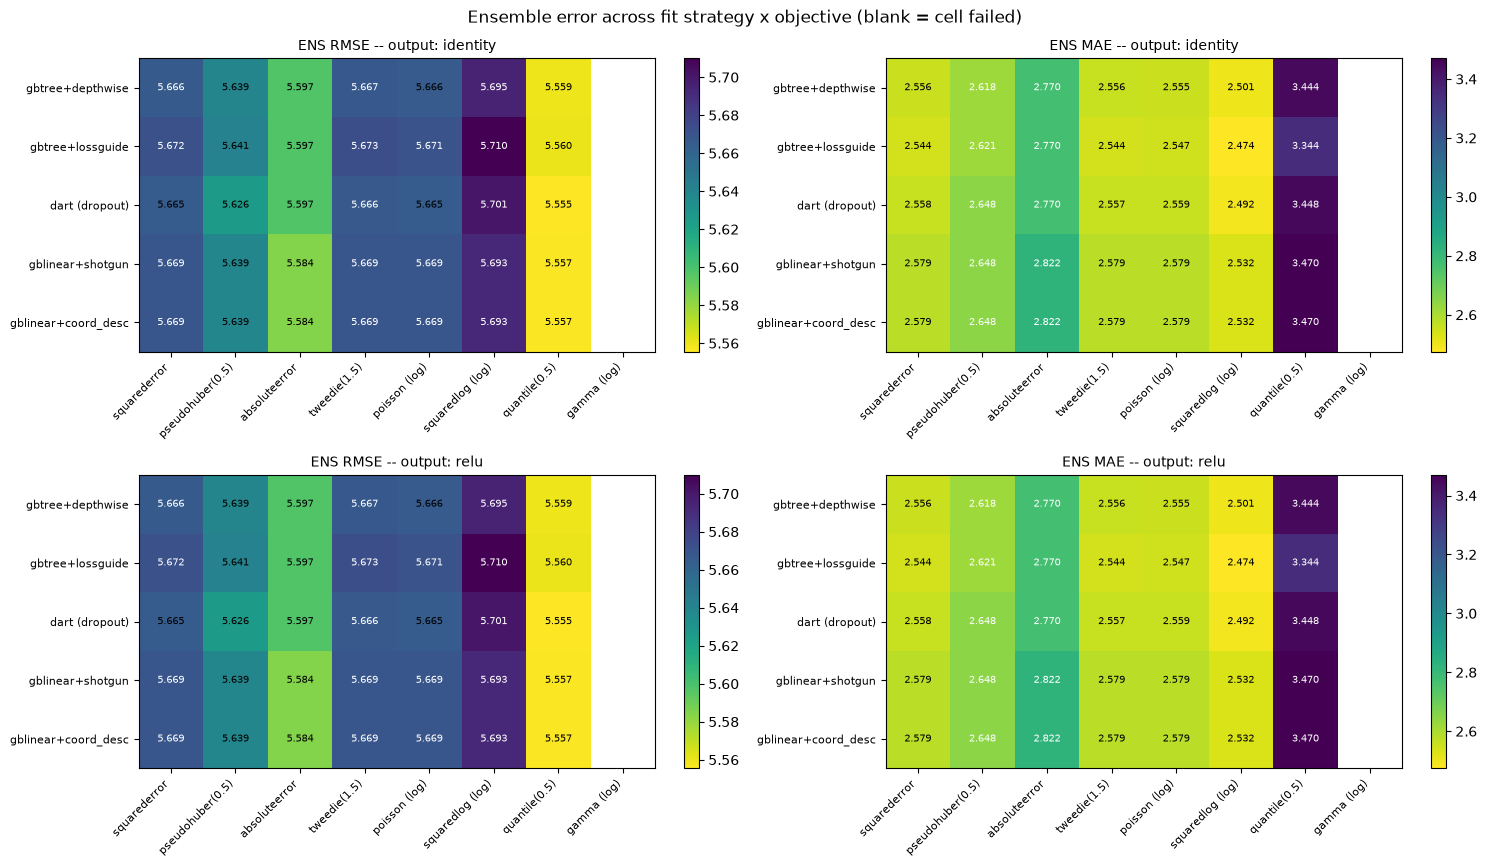

In [16]:
# ---------------------------------------------------------------------------
# Figure 1: ensemble RMSE and MAE across fit strategy x objective
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(len(OUTPUT_TRANSFORMS), 2,
                         figsize=(15, 4.4 * len(OUTPUT_TRANSFORMS)), squeeze=False)
fit_order = list(FIT_STRATEGIES)
obj_order = list(OBJECTIVES)

for r, transform in enumerate(OUTPUT_TRANSFORMS):
    sub = ok[ok['Output'] == transform]
    for c, metric in enumerate(['ENS RMSE', 'ENS MAE']):
        ax = axes[r][c]
        grid = (sub.pivot_table(index='Fit strategy', columns='Objective', values=metric)
                   .reindex(index=fit_order, columns=obj_order))
        im = ax.imshow(grid.values.astype(float), cmap='viridis_r', aspect='auto')
        ax.set_xticks(range(len(obj_order)))
        ax.set_xticklabels(obj_order, rotation=45, ha='right', fontsize=8)
        ax.set_yticks(range(len(fit_order)))
        ax.set_yticklabels(fit_order, fontsize=8)
        ax.set_title(f"{metric} -- output: {transform}", fontsize=10)
        med = np.nanmedian(grid.values.astype(float))
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                v = float(grid.values[i, j]) if grid.values[i, j] is not None else np.nan
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.3f}", ha='center', va='center', fontsize=7,
                            color='white' if v > med else 'black')
        fig.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle('Ensemble error across fit strategy x objective (blank = cell failed)', fontsize=12)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'grid_heatmaps.png', dpi=130, bbox_inches='tight')
plt.show()

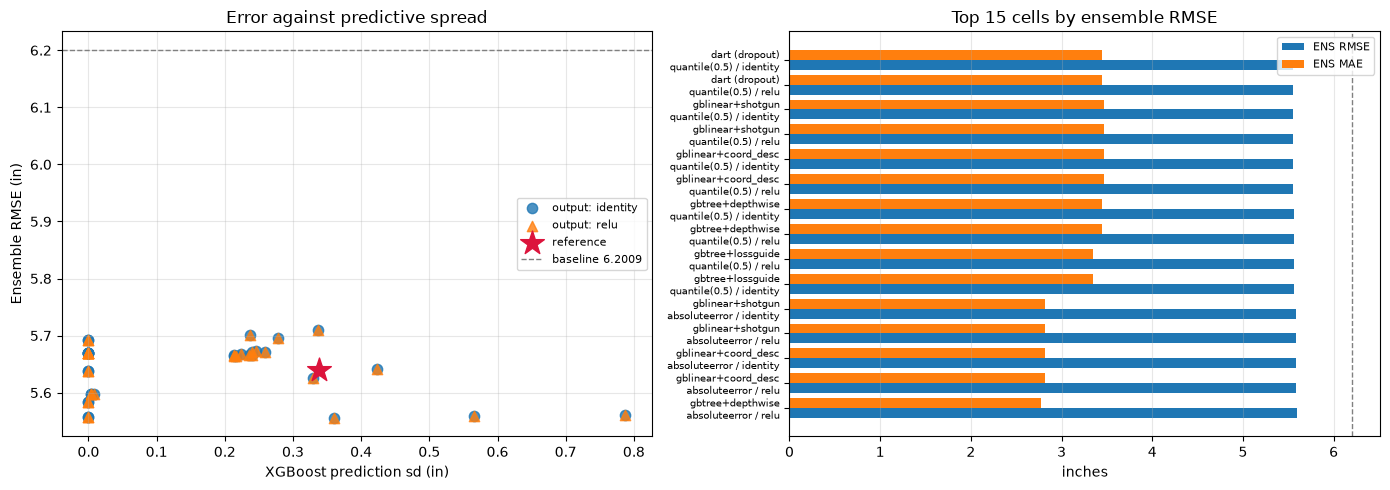

In [17]:
# ---------------------------------------------------------------------------
# Figure 2: error against predictive spread, and the leaderboard.
# Cells that score well on error while predicting almost a constant are the
# ones to distrust -- that is shrinkage, not skill.
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for transform, marker in zip(OUTPUT_TRANSFORMS, ['o', '^']):
    sub = ok[ok['Output'] == transform]
    ax.scatter(sub['XGB pred sd'], sub['ENS RMSE'], marker=marker, s=55, alpha=0.8,
               label=f"output: {transform}")
if len(ref):
    ax.scatter([ref.iloc[0]['XGB pred sd']], [ref.iloc[0]['ENS RMSE']], marker='*',
               s=320, color='crimson', zorder=5, label='reference')
ax.axhline(BASELINE_RMSE, ls='--', lw=1, color='gray', label=f'baseline {BASELINE_RMSE}')
ax.set_xlabel('XGBoost prediction sd (in)')
ax.set_ylabel('Ensemble RMSE (in)')
ax.set_title('Error against predictive spread')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
top = ok.sort_values('ENS RMSE').head(15).iloc[::-1]
labels = [f"{r['Fit strategy']}\n{r['Objective']} / {r['Output']}" for _, r in top.iterrows()]
ypos = np.arange(len(top))
ax.barh(ypos - 0.2, top['ENS RMSE'], height=0.4, label='ENS RMSE')
ax.barh(ypos + 0.2, top['ENS MAE'], height=0.4, label='ENS MAE')
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=7)
ax.axvline(BASELINE_RMSE, ls='--', lw=1, color='gray')
ax.set_xlabel('inches')
ax.set_title('Top 15 cells by ensemble RMSE')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(MODEL_DIR / 'grid_tradeoff.png', dpi=130, bbox_inches='tight')
plt.show()

In [18]:
# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
results = {
    'model_type': 'LSTM_XGBoost_activation_optimizer_experiment',
    'derived_from': 'runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb',
    'lstm': {
        'source': str(STATIC_DIR / 'lstm_model.keras'),
        'retrained': False,
        'reason': 'LSTM is frozen project-wide; dropout is inactive at inference so the '
                  'saved model reproduces its training-time predictions exactly.',
        'verified_against_metadata': True,
        'test_metrics': lstm_metrics,
    },
    'hyperparameter_search': {
        'technique': 'ParameterSampler random search + local refinement pass',
        'source': 'LSTM_XGBoost_Ensemble_Precipitation_REFACTORED 2.2.ipynb '
                  '(cell 7 space, cell 23 procedure)',
        'space': XGB_PARAM_DISTRIBUTIONS,
        'n_draws': XGB_N_ITER_SEARCH,
        'n_refine': XGB_N_ITER_REFINE,
        'n_fits': searched_n_fits,
        'criterion': 'RMSE in inches on the last 12% of training, chronological',
        'selected': SEARCHED_PARAMS,
        'selected_validation_rmse': searched_val_rmse,
        'search_seconds': search_seconds,
        'searched_per_cell': SEARCH_PER_CELL,
    },
    'ensemble': {
        'strategy': 'Inverse RMSE weighting, derived per grid cell',
        'formula': 'w_i = (1/RMSE_i) / sum_j(1/RMSE_j), RMSE on the last 8% of training',
        'lstm_validation_rmse': rmse_lstm_val,
        'hardcoded': False,
    },
    'experiment': {
        'fit_strategies': FIT_STRATEGIES,
        'strategy_pinned_params': list(STRATEGY_PINNED),
        'objectives': OBJECTIVES,
        'output_transforms': OUTPUT_TRANSFORMS,
        'reference_cell': [REFERENCE_FIT, REFERENCE_OBJECTIVE, REFERENCE_TRANSFORM],
        'n_cells': len(df_grid),
        'n_ok': n_ok,
        'grid_seconds': grid_seconds,
        'terminology_note': 'XGBoost has no optimizer or activation function. Fit strategy '
                            '(booster / updater / grow_policy) stands in for the optimizer, '
                            'objective (link + loss shape) for the activation, and '
                            'max(0, yhat) is a literal ReLU on the output.',
    },
    'preprocessing': {
        'box_cox_lambda': float(lam_value),
        'scaler_type': 'MinMaxScaler (loaded from models/v2_static/scaler.joblib)',
        'inverse_transform_asymptote': float(BC_UPPER),
    },
    'baseline_reference': {'rmse': BASELINE_RMSE, 'mae': BASELINE_MAE, 'mape': BASELINE_MAPE},
    'grid_results': df_grid.replace({np.nan: None}).to_dict(orient='records'),
    'summary': df_summary.replace({np.nan: None}).to_dict(orient='records'),
}

with open(MODEL_DIR / 'metadata.json', 'w') as f:
    json.dump(results, f, indent=4, default=float)

np.savez_compressed(
    MODEL_DIR / 'predictions.npz',
    y_test_orig=y_test_orig,
    lstm=lstm_pred_orig,
    **{f"{f}|{o}|{t}|{kind}": v[kind]
       for (f, o, t), v in grid_predictions.items() for kind in ('xgb', 'ensemble')},
)

print(f"Saved metadata to {MODEL_DIR / 'metadata.json'}")
print(f"Saved per-cell predictions to {MODEL_DIR / 'predictions.npz'}")
print(f"Saved results table to {RESULTS_CSV}")
print(f"Saved figures to {MODEL_DIR / 'grid_heatmaps.png'} and "
      f"{MODEL_DIR / 'grid_tradeoff.png'}")

Saved metadata to models\v2_activation_optimizer_exp\metadata.json
Saved per-cell predictions to models\v2_activation_optimizer_exp\predictions.npz
Saved results table to models\v2_activation_optimizer_exp\grid_results.csv
Saved figures to models\v2_activation_optimizer_exp\grid_heatmaps.png and models\v2_activation_optimizer_exp\grid_tradeoff.png


In [19]:
# ---------------------------------------------------------------------------
# Guard: confirm models/v2_static/ was not modified. That directory holds the
# artifacts the Streamlit site loads.
# ---------------------------------------------------------------------------
after = sha256_dir(STATIC_DIR)
if after == STATIC_HASHES_ON_ENTRY:
    print(f"[OK] {STATIC_DIR} unchanged -- all {len(after)} files match their entry hashes.")
    print("     The deployed artifacts were read, never written.")
else:
    changed = sorted({k for k in set(after) | set(STATIC_HASHES_ON_ENTRY)
                      if after.get(k) != STATIC_HASHES_ON_ENTRY.get(k)})
    raise RuntimeError(f"{STATIC_DIR} was modified: {changed}")

[OK] models\v2_static unchanged -- all 4 files match their entry hashes.
     The deployed artifacts were read, never written.
